# 05 학습 ① 분류 모델 확장: 확신도 보정 · 처음 보는 음식 감지 (Colab · GPU 있으면 빠름, **없어도 됨**)
ConvNeXt-Tiny(학습 ①)의 **확신도를 믿을 수 있게 고치고**, **처음 보는 음식을 알아채는 법**을 비교해서, `judge.py`의 임시 기준값 `T_ONE 0.8`, `T_KNOWN 0.3`을 **숫자 근거로** 정한다.

| 파트 | 하는 일 | 보여주는 것 (결과 표 → `찍먹_실험기록/표/`) |
|---|---|---|
| ① | `modeling/model.py`가 `best.pt`와 맞는지 확인 | 후보 3개 + 확률이 정상으로 나옴 |
| ② | 확신도 보정 (temperature scaling) | 보정 전/후 ECE → `보정_결과_<모델>.csv` |
| ③ | 처음 보는 음식 감지: 최대 확률(MSP) vs energy 점수 | AUROC, FPR@TPR95 → `감지_결과_<모델>.csv` |
| ⑤ | `T_ONE`·`T_KNOWN` 정하기 | 기준값 + 근거 숫자 → `기준값_결과_<모델>.csv` |

④(outlier exposure 추가 학습)는 여유가 생기면 별도 노트북으로 한다.

**어떤 모델로 돌리나**: 셀 0의 `MODEL` 한 줄로 고른다. `'base'` = 한솔님 ConvNeXt-Base(timm, `hansol_train_convnext`로 학습), `'tiny'` = 지금 앱의 ConvNeXt-Tiny(`modeling/model.py`).
둘 다 한 번씩 돌리면 **보정 전/후 ECE, 처음 보는 음식 감지, CPU 속도**를 모델끼리 비교할 수 있어서 두 번째 발표의 "모델을 고른 근거"로 쓸 수 있다. 결과 파일 이름 끝에 `_base`/`_tiny`가 붙는다.

**데이터 나누기 (같은 사진을 정하는 데와 채점하는 데 같이 쓰지 않는다)**
- 아는 음식: 팀 공용 분할(`data/splits`)을 그대로 쓴다. **val**(음식마다 75장, 7,575장)로 보정·기준값을 정하고 **test**(공식 시험 25,250장)로 최종 채점한다. 분할 목록은 한솔님 학습 노트북 셀 3과 같은 방법으로 다시 만든다.
- 처음 보는 음식: `candidates.csv` 새 후보 74종 중 사진 30장 이상인 것. **음식 단위로 반반** (기준값용 / 최종 채점용).

## 0. 드라이브 연결 · 코드 받기 (04 첫 셀과 같음)

In [1]:
import os, sys, io, glob, random, subprocess, unicodedata
from google.colab import drive
drive.mount('/content/drive')

def find(parent, name):
    for d in os.listdir(parent):
        if unicodedata.normalize('NFC', d).strip() == name:
            return f'{parent}/{d}'
    raise FileNotFoundError(f"'{parent}' 안에 '{name}' 없음. 보이는 폴더: {sorted(os.listdir(parent))}")

TEAM = find('/content/drive/MyDrive', '26-2 딥러닝')
DATA = f'{TEAM}/data1'
IMG = f'{DATA}/images'                      # 03에서 모은 사진 (처음 보는 음식으로 씀)
EXP = find(TEAM, '찍먹_실험기록')
OUT = f'{EXP}/표'                           # 결과 표
MODEL = 'base_exp004'                       # 'base_exp004' = 한솔 최종 모델(exp004, 앱 사용) / 'base' = exp003 / 'tiny' = 처음 ConvNeXt-Tiny
BEST = f'{EXP}/best/convnext_{MODEL}'       # best.pt가 있는 곳 (base는 서버 hansol/checkpoints/.../best.pt를 이 폴더에 복사). 중간 결과(logits)도 여기에 저장
os.makedirs(OUT, exist_ok=True); os.makedirs(BEST, exist_ok=True)
SPLITS_DIR = None    # 서버 food101/data/splits (train/val/test.csv)를 드라이브에 복사했다면 그 경로. 없으면 같은 방법으로 다시 만든다

REPO = '/content/deeplearning_5'
if not os.path.exists(REPO):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/yura103/deeplearning_5', REPO], check=True)
else:
    subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)
sys.path.insert(0, REPO)

import torch
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(os.cpu_count())
FAST = (dev == 'cpu')        # GPU가 없으면 사진 수를 줄여서 돌린다 (원하면 직접 True/False로 바꿔도 됨)
N_VAL, N_TEST, N_UNSEEN = (20, 20, 30) if FAST else (75, 250, 100)   # val/test/처음 보는 음식: 음식마다 쓰는 사진 수
print('준비 완료 |', torch.cuda.get_device_name() if dev == 'cuda' else 'GPU 없음 → CPU, 사진 수를 줄여서 돌림', f'| 음식당 val {N_VAL} · test {N_TEST} · 처음 보는 음식 {N_UNSEEN}장')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
준비 완료 | Tesla T4 | 음식당 val 75 · test 250 · 처음 보는 음식 100장


## 1. Food-101 풀기 + ① 모델이 `best.pt`와 맞는지 확인
Food-101 압축 풀기에 5~10분 걸린다 (이미 풀려 있으면 건너뜀).
모델이 에러 없이 불러와지고, 사진 한 장에 후보 3개 + 확률이 나오면 ① 끝 (정답 클래스가 1등이면 정상). `MODEL='tiny'`면 앱의 `modeling/model.py`를 그대로 쓰므로 그 파일이 `best.pt`와 맞는지 확인이 된다.
`MODEL='base'`면 `best.pt`를 `찍먹_실험기록/best/convnext_base/`에 먼저 복사해 둔다 (서버 `hansol/checkpoints/convnext/initial/<실험이름>/best.pt`).

In [2]:
from PIL import Image
import numpy as np, pandas as pd
import torchvision.transforms as Tv

F101 = '/content/food-101'
if not os.path.exists(f'{F101}/meta/test.txt'):
    subprocess.run(['tar', 'xzf', f'{DATA}/food-101.tar.gz', '-C', '/content'], check=True)
test = open(f'{F101}/meta/test.txt').read().split()          # 'apple_pie/1011328' 꼴, 101종 × 250장
classes = open(f'{REPO}/modeling/classes.txt').read().split()
assert len(classes) == 101, len(classes)
assert classes == open(f'{F101}/meta/classes.txt').read().split(), 'classes.txt 순서가 Food-101과 다름 → 라벨이 어긋남'

if MODEL == 'tiny':
    from modeling.model import load_model, predict, TF       # 앱이 쓰는 그대로
    bundle = load_model(f'{BEST}/best.pt', f'{REPO}/modeling/classes.txt')
    net = bundle[0]
else:
    import timm                                              # 한솔 학습 노트북과 같은 모델 (timm convnext_base)
    net = timm.create_model('convnext_base.fb_in22k_ft_in1k', pretrained=False, num_classes=101)
    ck = torch.load(f'{BEST}/best.pt', map_location='cpu', weights_only=False)
    net.load_state_dict(ck['model']); net.eval()             # best.pt의 'model' = EMA 가중치 (학습 노트북 셀 8)
    # 학습 노트북의 평가 전처리와 같음: 256으로 키운 뒤(bicubic) 가운데 224 크롭, ImageNet 정규화
    TF = Tv.Compose([Tv.Resize(256, interpolation=Tv.InterpolationMode.BICUBIC), Tv.CenterCrop(224),
                     Tv.ToTensor(), Tv.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

p = test[0]
with torch.no_grad():
    pr = net.eval()(TF(Image.open(f'{F101}/images/{p}.jpg').convert('RGB'))[None]).softmax(1)[0]
print(MODEL, '|', p, '→', [(classes[i], round(float(pr[i]), 3)) for i in pr.topk(3).indices])   # 정답 클래스가 1등이면 정상
net = net.to(dev)

base | apple_pie/1011328 → [('samosa', 0.384), ('apple_pie', 0.308), ('gyoza', 0.034)]


## 2. 사진마다 logits 뽑기 (아는 음식 / 처음 보는 음식)
- **GPU가 없으면** 셀 0이 자동으로 `FAST` 모드가 되어 음식마다 val 20 · test 20 · 처음 보는 음식 30장(총 약 6천 장)만 쓴다. 숫자의 정밀도는 조금 떨어지지만 보정·감지 비교에는 충분하고, 시간은 모델·CPU에 따라 크게 다르다 (Tiny는 보통 수십 분, Base는 더 오래).
- **logits** = 모델이 확률(softmax)을 만들기 직전의 점수. 보정·감지 계산은 전부 이 숫자로 하므로, 한 번만 뽑아 저장해 두면 그 뒤 실험이 몇 초에 끝난다.
- 처음 보는 음식: 사진 30장 미만이거나 가짜(`_fake_md5.csv`) 사진은 뺀다. 음식당 최대 `N_UNSEEN`장 (음식마다 비중 비슷하게).

In [3]:
from torch.utils.data import Dataset, DataLoader

class Photos(Dataset):
    def __init__(self, srcs): self.s = srcs                  # 파일 경로(str) 또는 JPEG 바이트
    def __len__(self): return len(self.s)
    def __getitem__(self, i):
        s = self.s[i]
        return TF(Image.open(s if isinstance(s, str) else io.BytesIO(s)).convert('RGB'))

@torch.no_grad()
def get_logits(srcs, bs=None):
    bs = bs or (128 if dev == 'cuda' else 32)              # CPU는 메모리가 작아 배치를 줄임
    net.eval(); out = []
    for x in DataLoader(Photos(srcs), bs, num_workers=2):
        out.append(net(x.to(dev)).float().cpu().numpy())
    return np.concatenate(out)

LOGITS = f'{BEST}/logits_05_{MODEL}_{"fast" if FAST else "full"}.npz'
if os.path.exists(LOGITS):
    z = np.load(LOGITS, allow_pickle=True)
    print('저장된 logits 사용:', LOGITS)
else:
    # 아는 음식: 공용 분할 (학습 노트북 셀 3과 같은 방법). a = val(보정·기준값용), b = test(최종 채점용)
    if SPLITS_DIR:                                           # 서버 food101/data/splits 를 드라이브에 복사해 뒀다면 그대로 읽음
        import csv
        read = lambda n: [r[0] for r in list(csv.reader(open(f'{SPLITS_DIR}/{n}.csv')))[1:]]
        pa, pb = read('val'), read('test')
    else:
        EXCLUDE = {'steak/1340977', 'lasagna/3787908', 'bread_pudding/1375816'}   # 중간발표 EDA에서 뺀 흑백 오류 3장
        tr_all = [l for l in open(f'{F101}/meta/train.txt').read().split() if l not in EXCLUDE]
        by = {}
        for i in tr_all: by.setdefault(i.split('/')[0], []).append(i)
        rng, pa = random.Random(42), []
        for c in classes:                                    # 클래스 순서 = classes.txt (= Food-101 meta/classes.txt)
            ids = sorted(by[c]); rng.shuffle(ids); pa += ids[:75]
        pb = test
        assert (len(pa), len(pb)) == (7575, 25250), (len(pa), len(pb))
    if (N_VAL, N_TEST) != (75, 250):                         # GPU 없을 때: 음식마다 N장만 무작위로 (시드 고정, 음식별 균등)
        def per_class(ids, n, seed):
            g, r = {}, random.Random(seed)
            for i in ids: g.setdefault(i.split('/')[0], []).append(i)
            return [i for c in classes for i in (g[c] if n >= len(g[c]) else r.sample(g[c], n))]
        pa, pb = per_class(pa, N_VAL, 0), per_class(pb, N_TEST, 1)
    path = lambda p: f'{F101}/images/{p}.jpg'
    idx = {c: i for i, c in enumerate(classes)}
    ya = np.array([idx[p.split('/')[0]] for p in pa]); yb = np.array([idx[p.split('/')[0]] for p in pb])
    La = get_logits([path(p) for p in pa]); Lb = get_logits([path(p) for p in pb])

    # 처음 보는 음식: 새 후보 74종 (분류 모델이 모르는 음식)
    fake = set(pd.read_csv(f'{IMG}/_fake_md5.csv').md5)
    cand = pd.read_csv(f'{REPO}/knowledge/candidates.csv')['class'].tolist()
    assert not set(cand) & set(classes), '새 후보에 아는 음식이 섞여 있음'
    ph = []
    for c in cand:
        f = f'{IMG}/{c}.parquet'
        if not os.path.exists(f): continue
        d = pd.read_parquet(f, columns=['label', 'md5', 'jpg'])
        d = d[~d.md5.isin(fake)]
        if len(d) >= 30: ph.append(d.sample(frac=1, random_state=0).head(N_UNSEEN))
    ph = pd.concat(ph).reset_index(drop=True)
    uc = sorted(ph.label.unique()); perm = list(np.random.default_rng(1).permutation(uc)); h = len(perm) // 2
    dev_cls, ev_cls = set(perm[:h]), set(perm[h:])
    Ud = get_logits(ph[ph.label.isin(dev_cls)].jpg.tolist()); Ue = get_logits(ph[ph.label.isin(ev_cls)].jpg.tolist())

    np.savez(LOGITS, La=La, ya=ya, Lb=Lb, yb=yb, Ud=Ud, Ue=Ue,
             dev_cls=np.array(sorted(dev_cls)), ev_cls=np.array(sorted(ev_cls)))
    z = np.load(LOGITS, allow_pickle=True)

La, ya, Lb, yb, Ud, Ue = (z[k] for k in ['La', 'ya', 'Lb', 'yb', 'Ud', 'Ue'])
print(f'[{"FAST" if FAST else "FULL"}] 아는 음식  val(보정·기준값용) {La.shape[0]:,}장 | test(채점용) {Lb.shape[0]:,}장')
print(f'처음 보는 음식  기준값용 {Ud.shape[0]:,}장 ({len(z["dev_cls"])}종) | 채점용 {Ue.shape[0]:,}장 ({len(z["ev_cls"])}종)')

[FULL] 아는 음식  val(보정·기준값용) 7,575장 | test(채점용) 25,250장
처음 보는 음식  기준값용 2,221장 (25종) | 채점용 2,114장 (26종)


## 3. ② 확신도 보정 (temperature scaling)
- 확신도 = `softmax(logits / T)`. 모델은 보통 **실제보다 더 확신**한다 (T > 1이면 그렇다는 뜻). `T` 하나를 **보정용 사진**에서 찾고, **채점용 사진**에서 효과를 본다.
- **ECE** = "확신도 0.9인 사진의 실제 정답률이 얼마나 0.9에 가까운가"의 평균 차이 (낮을수록 좋음). NLL도 같이 본다. 정확도(top1)는 T를 바꿔도 변하지 않는다.

In [4]:
from scipy.special import logsumexp, softmax
from scipy.optimize import minimize_scalar
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

def nll(L, y, T=1.0):
    z = L / T
    return float(np.mean(logsumexp(z, axis=1) - z[np.arange(len(y)), y]))

def ece(P, y, bins=15):
    conf, ok = P.max(1), (P.argmax(1) == y)
    e, edges = 0.0, np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(e)

T = float(minimize_scalar(lambda t: nll(La, ya, t), bounds=(0.05, 10), method='bounded').x)
print(f'온도 T = {T:.3f}  (1보다 크면 과신 → 확신도를 낮춰 준다)')

rows = []
for tag, t in [('보정 전 (T=1)', 1.0), ('보정 후', T)]:
    P = softmax(Lb / t, axis=1)
    rows.append({'모델': MODEL, '상태': tag, 'T': round(t, 3), 'top1': (P.argmax(1) == yb).mean(), 'NLL': nll(Lb, yb, t), 'ECE': ece(P, yb)})
res_cal = pd.DataFrame(rows).round(4)
res_cal.to_csv(f'{OUT}/보정_결과_{MODEL}.csv', index=False, encoding='utf-8-sig')
display(res_cal)

온도 T = 0.838  (1보다 크면 과신 → 확신도를 낮춰 준다)


,모델,상태,T,top1,NLL,ECE
0,base,보정 전 (T=1),1.000,0.9337,0.3074,0.0651
1,base,보정 후,0.838,0.9337,0.2591,0.0174


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45813 (\N{HANGUL SYLLABLE DAB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/us

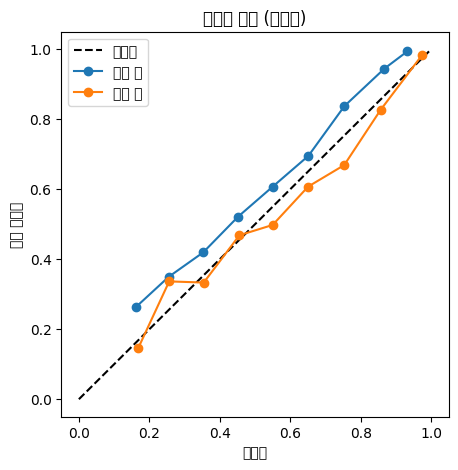

In [5]:
# 신뢰도 도표: 대각선에 가까울수록 "확신도 = 실제 정답률"
def curve(P, y, bins=10):
    conf, ok = P.max(1), (P.argmax(1) == y); edges = np.linspace(0, 1, bins + 1); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 20: xs.append(conf[m].mean()); ys.append(ok[m].mean())
    return xs, ys

plt.figure(figsize=(5, 5)); plt.plot([0, 1], [0, 1], 'k--', label='이상적')
for tag, t in [('보정 전', 1.0), ('보정 후', T)]:
    plt.plot(*curve(softmax(Lb / t, axis=1), yb), 'o-', label=tag)
plt.xlabel('확신도'); plt.ylabel('실제 정답률'); plt.legend(); plt.title('신뢰도 도표 (채점용)'); plt.show()

## 4. ③ 처음 보는 음식 감지: 최대 확률 vs energy 점수
- **MSP**: 1등 확률. 낮으면 모르는 음식 같다. (지금 `judge.py`가 쓰는 방식)
- **energy**: `T·logsumexp(logits/T)`. 클수록 아는 음식 같다 (`-energy`). 확률로 바꾸기 전 점수라 "전부 낮게 확신 못 함"을 더 잘 잡는다고 알려져 있다.
- 점수는 모두 **클수록 아는 음식**으로 통일. 아는 음식 = 채점용 Food-101, 모르는 음식 = 채점용 새 후보(음식 단위로 분리된 쪽).
- **AUROC**: 높을수록 좋음 (1 = 완벽). **FPR@TPR95**: 아는 음식의 95%를 통과시킬 때 모르는 음식이 잘못 통과되는 비율, **낮을수록 좋음**.

In [6]:
def s_msp(L, t=1.0):    return softmax(L / t, axis=1).max(1)
def s_energy(L, t=1.0): return t * logsumexp(L / t, axis=1)

def detect(fn, t):
    s = np.concatenate([fn(Lb, t), fn(Ue, t)])
    y = np.r_[np.ones(len(Lb)), np.zeros(len(Ue))]
    fpr, tpr, _ = roc_curve(y, s)
    return roc_auc_score(y, s), float(fpr[np.searchsorted(tpr, 0.95)])

rows = []
for name, fn, t in [('최대 확률 MSP (T=1)', s_msp, 1.0), ('최대 확률 MSP (보정 T)', s_msp, T),
                    ('energy (T=1)', s_energy, 1.0), ('energy (보정 T)', s_energy, T)]:
    a, f = detect(fn, t)
    rows.append({'모델': MODEL, '방법': name, 'AUROC': a, 'FPR@TPR95': f})
res_det = pd.DataFrame(rows).round(4)
res_det.to_csv(f'{OUT}/감지_결과_{MODEL}.csv', index=False, encoding='utf-8-sig')
display(res_det)

,모델,방법,AUROC,FPR@TPR95
0,base,최대 확률 MSP (T=1),0.8795,0.4570
1,base,최대 확률 MSP (보정 T),0.8796,0.4882
2,base,energy (T=1),0.8549,0.4101
3,base,energy (보정 T),0.8594,0.4092


## 5. ⑤ `T_ONE`·`T_KNOWN` 정하기
`judge.decide`는 **보정된 1등 확률**로 길을 나눈다: `≥ T_ONE` → 1등만 / `≥ T_KNOWN` → 상위 3개 합침 / 그 아래 → 2단계(CLIP).
- 표 A (`T_ONE`): 값을 올리면 1단계가 더 정확해지지만 2단계로 가는 사진이 늘어난다. **"모르는 음식 → 1단계" 비율**이 이 앱에서 제일 위험한 실수.
- 표 B (`T_KNOWN`): 값을 올리면 모르는 음식을 더 잡아내지만 아는 음식도 2단계(느림·덜 정확)로 간다. 합침 구간은 상위 3개 안에 정답이 있어야 의미가 있다.
- **정하는 규칙** (아래 숫자를 바꾸면 규칙이 바뀐다): `T_ONE` = 1단계 정답률이 `목표 이상`이 되는 가장 작은 값, `T_KNOWN` = 합침 구간의 top3 적중이 `목표 이상`이 되는 가장 작은 값.
- 기준값은 **보정용·기준값용** 사진(`La`, `Ud`)으로 정하고, 마지막에 **채점용**(`Lb`, `Ue`)으로 다시 잰다.

In [7]:
TARGET_ACC_ONE, TARGET_TOP3_MERGE = 0.95, 0.90        # 규칙의 목표 (바꿔 보면 기준값이 어떻게 움직이는지 볼 수 있다)

def top3_hit(P, y):
    return np.array([y[i] in np.argsort(-P[i])[:3] for i in range(len(y))])

def stats(Lk, yk, Lu, t_one, t_known, temp=None):
    temp = T if temp is None else temp                    # 기본은 보정된 T, 임시값 비교 때만 1.0
    Pk, Pu = softmax(Lk / temp, axis=1), softmax(Lu / temp, axis=1)
    ck, cu = Pk.max(1), Pu.max(1)
    ok, h3 = (Pk.argmax(1) == yk), top3_hit(Pk, yk)
    s1, mid, s2 = ck >= t_one, (ck >= t_known) & (ck < t_one), ck < t_known
    return {'아는음식→1단계': s1.mean(), '1단계 정답률': ok[s1].mean() if s1.any() else np.nan,
            '아는음식→합침': mid.mean(), '합침 top3 적중': h3[mid].mean() if mid.any() else np.nan,
            '아는음식→2단계': s2.mean(), '모르는음식→1단계': (cu >= t_one).mean(),
            '모르는음식→합침': ((cu >= t_known) & (cu < t_one)).mean(), '모르는음식→2단계(잡힘)': (cu < t_known).mean()}

grid_one = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98]
grid_known = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]

A = pd.DataFrame([{'T_ONE': t, **{k: v for k, v in stats(La, ya, Ud, t, 0.0).items()
                  if k in ('아는음식→1단계', '1단계 정답률', '모르는음식→1단계')}} for t in grid_one]).round(3)
print('표 A. T_ONE (기준값용 사진)'); display(A)

ok_one = A[A['1단계 정답률'] >= TARGET_ACC_ONE]
T_ONE = float(ok_one.T_ONE.min()) if len(ok_one) else float(A.T_ONE.max())
B = pd.DataFrame([{'T_KNOWN': t, **{k: v for k, v in stats(La, ya, Ud, T_ONE, t).items()
                  if k in ('아는음식→합침', '합침 top3 적중', '아는음식→2단계', '모르는음식→2단계(잡힘)')}}
                  for t in grid_known if t < T_ONE]).round(3)
print(f'표 B. T_KNOWN (T_ONE = {T_ONE} 로 고정, 기준값용 사진)'); display(B)

ok_known = B[B['합침 top3 적중'] >= TARGET_TOP3_MERGE]
T_KNOWN = float(ok_known.T_KNOWN.min()) if len(ok_known) else float(B.T_KNOWN.max())

표 A. T_ONE (기준값용 사진)


,T_ONE,아는음식→1단계,1단계 정답률,모르는음식→1단계
0,0.50,0.955,0.926,0.690
1,0.60,0.932,0.937,0.599
2,0.70,0.906,0.949,0.517
3,0.80,0.873,0.960,0.427
4,0.85,0.851,0.966,0.379
5,0.90,0.817,0.974,0.315
6,0.95,0.741,0.982,0.228
7,0.98,0.383,0.990,0.088


표 B. T_KNOWN (T_ONE = 0.8 로 고정, 기준값용 사진)


,T_KNOWN,아는음식→합침,합침 top3 적중,아는음식→2단계,모르는음식→2단계(잡힘)
0,0.1,0.126,0.808,0.001,0.007
1,0.2,0.122,0.824,0.005,0.058
2,0.3,0.116,0.835,0.012,0.135
3,0.4,0.103,0.856,0.024,0.225
4,0.5,0.082,0.880,0.045,0.310
5,0.6,0.059,0.881,0.068,0.401


In [8]:
# 정한 값을 채점용 사진으로 다시 잰다 + 지금 임시값(T=1, 0.8 / 0.3)과 비교
final = pd.DataFrame([
    {'모델': MODEL, '기준': '임시값 (보정 없음 · 0.8 / 0.3)', **stats(Lb, yb, Ue, 0.8, 0.3, temp=1.0)},
    {'모델': MODEL, '기준': f'새 기준 (T={T:.2f} · {T_ONE} / {T_KNOWN})', **stats(Lb, yb, Ue, T_ONE, T_KNOWN)},
]).round(3)
final.to_csv(f'{OUT}/기준값_결과_{MODEL}.csv', index=False, encoding='utf-8-sig')
display(final.drop(columns='모델').set_index('기준').T)

print()
print(f'=== 팀에 알릴 값 (모델: {MODEL}) ===')
if MODEL == 'tiny':
    print(f'modeling/model.py : TEMPERATURE = {T:.3f}')
else:
    print(f'Base 보정 온도 T = {T:.3f}  (지금 앱 model.py는 Tiny라 바로 넣지 말 것. Base를 앱에 쓰기로 정한 뒤 model.py를 timm 기반으로 바꿀 때 사용)')
print(f'knowledge/judge.py: T_ONE, T_KNOWN = {T_ONE}, {T_KNOWN}   (모델마다 값이 다르다)')

기준,임시값 (보정 없음 · 0.8 / 0.3),새 기준 (T=0.84 · 0.8 / 0.6)
아는음식→1단계,0.848,0.904
1단계 정답률,0.985,0.975
아는음식→합침,0.141,0.050
합침 top3 적중,0.936,0.926
아는음식→2단계,0.011,0.046
모르는음식→1단계,0.223,0.331
모르는음식→합침,0.487,0.170
모르는음식→2단계(잡힘),0.290,0.499



=== 팀에 알릴 값 (모델: base) ===
Base 보정 온도 T = 0.838  (지금 앱 model.py는 Tiny라 바로 넣지 말 것. Base를 앱에 쓰기로 정한 뒤 model.py를 timm 기반으로 바꿀 때 사용)
knowledge/judge.py: T_ONE, T_KNOWN = 0.8, 0.6   (모델마다 값이 다르다)


## 6. 서버 CPU 속도 (모델 고르는 근거)
앱 서버는 GPU 없이 CPU로 사진 1장씩 처리한다. 모델이 클수록 느려서 "정확도 vs 응답 시간" 근거로 쓴다 (04 7번과 같은 방법: 1장씩 30번 평균).
**Colab CPU는 학과 서버와 다르므로 참고용**이다. 발표 숫자는 학과 서버에서 `MODEL`을 바꿔가며 이 셀만 다시 재는 게 정확하다.

In [9]:
import time
net_cpu = net.float().cpu().eval()
x = TF(Image.open(f'{F101}/images/{test[0]}.jpg').convert('RGB'))[None]
torch.set_num_threads(os.cpu_count())
with torch.no_grad():
    for _ in range(3): net_cpu(x)
    t0 = time.perf_counter()
    for _ in range(30): net_cpu(x)
ms = (time.perf_counter() - t0) / 30 * 1000
params_m = sum(p.numel() for p in net_cpu.parameters()) / 1e6
res_speed = pd.DataFrame([{'모델': MODEL, '파라미터(M)': round(params_m, 1), 'CPU ms/장': round(ms, 1), 'CPU 스레드': os.cpu_count(),
                           '환경': 'Colab (참고용)'}])
res_speed.to_csv(f'{OUT}/CPU속도_{MODEL}.csv', index=False, encoding='utf-8-sig')
display(res_speed)

,모델,파라미터(M),CPU ms/장,CPU 스레드,환경
0,base,87.7,458.1,2,Colab (참고용)


## 끝 — 결과 읽는 법
- **보정_결과_<모델>.csv**: ECE가 보정 후 줄어들면 "확신도를 믿을 수 있게 됐다". (발표: 보정 전/후 ECE)
- **감지_결과_<모델>.csv**: AUROC가 높고 FPR@TPR95가 낮은 쪽이 처음 보는 음식을 더 잘 알아챈다. energy가 MSP보다 낫다면 `judge.decide`에 energy 조건을 추가하는 것을 팀과 상의한다 (함수 모양이 바뀌므로 먼저 맞출 것).
- **기준값_결과_<모델>.csv**: 새 기준이 임시값보다 **"모르는음식→1단계"를 줄였는지** 가 핵심. 같은 줄에서 "아는음식→2단계"가 얼마나 늘었는지도 같이 본다 (안전 vs 속도 교환).
- 이 값들은 처음 보는 음식 **새 후보 사진**으로 잰 것이다. 실제 사용자 사진과 다를 수 있다는 한계를 발표에서 말한다.

`MODEL`을 `'tiny'`로 바꿔 한 번 더 돌리면 두 모델을 비교하는 표가 된다 (보정 전/후 ECE, 감지 AUROC, 기준값 결과, CPU 속도).

결과가 나오면: 앱에 쓸 모델의 값으로 `modeling/model.py`의 `TEMPERATURE`와 `judge.py`의 `T_ONE`·`T_KNOWN`을 바꾸는 PR을 올리고(브랜치 → PR), 값과 근거 숫자를 중현님에게 알린다.